In [5]:

import pandas as pd
import numpy as np

# Load dataset without automatically converting NA labels to NaN
df = pd.read_csv(
    "/kaggle/input/datasets/mirfanshahid/roman-urdu-abusive-comment-dataset-5000-comments/Cyber Dataset.csv",
    encoding="latin-1",
    keep_default_na=False
)

# Check all label values
print("Unique Classes:")
print(df["Classes"].unique())

# Count each label
print("\nLabel Counts:")
print(df["Classes"].value_counts(dropna=False))

# Check empty labels
print("\nEmpty Labels:", (df["Classes"].str.strip() == "").sum())


Unique Classes:
['A' 'NA' 'Na' 'A ' 'NA  ' 'A  ' 'NA ']

Label Counts:
Classes
NA      2656
A       2485
NA        13
A          5
Na         3
A          1
NA         1
Name: count, dtype: int64

Empty Labels: 0


In [6]:

# Clean Classes column
df["Classes"] = df["Classes"].str.strip().str.upper()

# Check cleaned labels
print("Unique Classes:")
print(df["Classes"].unique())

# Count cleaned labels
print("\nCleaned Label Counts:")
print(df["Classes"].value_counts())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Unique Classes:
['A' 'NA']

Cleaned Label Counts:
Classes
NA    2673
A     2491
Name: count, dtype: int64

Missing Values:
Comments    0
Classes     0
dtype: int64


In [9]:

# Count duplicate comments
duplicate_count = df["Comments"].duplicated().sum()

print("Total Duplicate Comments:", duplicate_count)

# Display duplicate comments
duplicates = df[df["Comments"].duplicated(keep=False)]

print("\nDuplicate Comments:")
display(duplicates.head(10))


Total Duplicate Comments: 213

Duplicate Comments:


,Comments,Classes
16,Tujhe samajh nahi aati kya?,A
80,"Chal bhaag yahan se, samjha?",A
91,Tujhe samajh nahi aati kya?,A
341,Bhen chod beghairat hukumat ka kaam yehe hea,A
343,Bhi phoddi ka tarsa hova,A
357,Bhen chod beghairat hukumat ka kaam yehe hea,A
361,Bhi phoddi ka tarsa hova,A
369,"Chal bhaag yahan se, samjha?",NA
510,Pakistan zindabad,NA
516,Pakistan zindabad,NA


In [10]:

# Check comments having more than one label
conflicts = df.groupby("Comments")["Classes"].nunique()

conflicts = conflicts[conflicts > 1]

print("Comments with Conflicting Labels:", len(conflicts))
print(conflicts.head(10))


Comments with Conflicting Labels: 2
Comments
Chal bhaag yahan se, samjha?                      2
India ap ne bade bahi Israel ko call karty hue    2
Name: Classes, dtype: int64


In [11]:

# Identify comments with conflicting labels
conflicts = df.groupby("Comments")["Classes"].nunique()
conflict_comments = conflicts[conflicts > 1].index

# Remove all rows containing conflicting comments
df = df[~df["Comments"].isin(conflict_comments)].copy()

print("Rows after removing conflicting labels:", len(df))

# Remove duplicate comments
df = df.drop_duplicates(subset=["Comments"], keep="first")

# Reset index
df = df.reset_index(drop=True)

# Display final results
print("\nDataset Shape:", df.shape)

print("\nRemaining Duplicate Comments:",
      df["Comments"].duplicated().sum())

print("\nFinal Label Counts:")
print(df["Classes"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())


Rows after removing conflicting labels: 5160

Dataset Shape: (4949, 2)

Remaining Duplicate Comments: 0

Final Label Counts:
Classes
NA    2616
A     2333
Name: count, dtype: int64

Missing Values:
Comments    0
Classes     0
dtype: int64


In [12]:

import re

# Function to clean Roman Urdu text
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply cleaning to Comments column
df["Cleaned_Comments"] = df["Comments"].apply(clean_text)


# Compare original and cleaned comments
print("Original vs Cleaned Comments:")

display(df[["Comments", "Cleaned_Comments"]].head(10))



Original vs Cleaned Comments:


,Comments,Cleaned_Comments
0,Tu bohot bekar aadmi hai.,tu bohot bekar aadmi hai
1,Aap ki baat bilkul sahi hai.,aap ki baat bilkul sahi hai
2,Chal nikal yahan se bewakoof!,chal nikal yahan se bewakoof
3,Yeh movie bohot achi thi.,yeh movie bohot achi thi
4,Tera dimagh kharab hai kya?,tera dimagh kharab hai kya
5,Mujhe tumhari baat pasand ayi.,mujhe tumhari baat pasand ayi
6,Tum bilkul pagal ho.,tum bilkul pagal ho
7,Bahut zabardast performance thi.,bahut zabardast performance thi
8,Tu kitna jahil hai.,tu kitna jahil hai
9,Aaj mausam bohot acha hai.,aaj mausam bohot acha hai


In [13]:

# Count duplicate cleaned comments
print("Duplicate Cleaned Comments:",
      df["Cleaned_Comments"].duplicated().sum())

# Find comments with conflicting labels after cleaning
cleaned_conflicts = df.groupby("Cleaned_Comments")["Classes"].nunique()

cleaned_conflicts = cleaned_conflicts[cleaned_conflicts > 1]

print("\nConflicting Cleaned Comments:",
      len(cleaned_conflicts))

print("\nConflict Details:")
display(df[df["Cleaned_Comments"].isin(cleaned_conflicts.index)])

# Check empty cleaned comments
print("\nEmpty Cleaned Comments:",
      (df["Cleaned_Comments"] == "").sum())


Duplicate Cleaned Comments: 57

Conflicting Cleaned Comments: 1

Conflict Details:


,Comments,Classes,Cleaned_Comments
2047,2No family,NA,2no family
2061,2no family,A,2no family



Empty Cleaned Comments: 0


In [15]:

# Identify conflicting cleaned comments
conflicts = df.groupby("Cleaned_Comments")["Classes"].nunique()

conflict_comments = conflicts[conflicts > 1].index

# Remove conflicting comments
df = df[~df["Cleaned_Comments"].isin(conflict_comments)].copy()

print("Rows after removing conflicts:", len(df))

# Remove duplicate cleaned comments
df = df.drop_duplicates(
    subset=["Cleaned_Comments"],
    keep="first"
)

# Reset index
df = df.reset_index(drop=True)

# Final dataset information
print("\nFinal Dataset Shape:", df.shape)

print("\nRemaining Duplicates:",
      df["Cleaned_Comments"].duplicated().sum())

print("\nFinal Class Distribution:")
print(df["Classes"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())




# Separate features and target
X = df["Cleaned_Comments"]
y = df["Classes"]

# Display information
print("Features (X):")
print(X.head())

print("\nTarget Labels (y):")
print(y.head())

print("\nTotal Features:", len(X))
print("Total Labels:", len(y))


Rows after removing conflicts: 4891

Final Dataset Shape: (4891, 3)

Remaining Duplicates: 0

Final Class Distribution:
Classes
NA    2601
A     2290
Name: count, dtype: int64

Missing Values:
Comments            0
Classes             0
Cleaned_Comments    0
dtype: int64
Features (X):
0        tu bohot bekar aadmi hai
1     aap ki baat bilkul sahi hai
2    chal nikal yahan se bewakoof
3        yeh movie bohot achi thi
4      tera dimagh kharab hai kya
Name: Cleaned_Comments, dtype: object

Target Labels (y):
0     A
1    NA
2     A
3    NA
4     A
Name: Classes, dtype: object

Total Features: 4891
Total Labels: 4891


In [16]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

print("\nTraining Label Distribution:")
print(y_train.value_counts())

print("\nTesting Label Distribution:")
print(y_test.value_counts())


Training Data: 3912
Testing Data: 979

Training Label Distribution:
Classes
NA    2080
A     1832
Name: count, dtype: int64

Testing Label Distribution:
Classes
NA    521
A     458
Name: count, dtype: int64


In [17]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create Machine Learning Pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000)),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Machine Learning Pipeline Created Successfully!")


Machine Learning Pipeline Created Successfully!


In [18]:

# Train the model using training data
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")


Model Training Completed Successfully!


In [19]:

# Predict labels for test data
y_pred = model.predict(X_test)

# Display first 10 predictions
print("Actual Labels:")
print(y_test.head(10).tolist())

print("\nPredicted Labels:")
print(y_pred[:10].tolist())


Actual Labels:
['NA', 'A', 'A', 'A', 'NA', 'A', 'A', 'NA', 'A', 'NA']

Predicted Labels:
['NA', 'A', 'NA', 'A', 'NA', 'A', 'A', 'NA', 'A', 'NA']


Model Accuracy: 79.16 %

Classification Report:
              precision    recall  f1-score   support

           A       0.82      0.71      0.76       458
          NA       0.77      0.87      0.82       521

    accuracy                           0.79       979
   macro avg       0.80      0.79      0.79       979
weighted avg       0.80      0.79      0.79       979



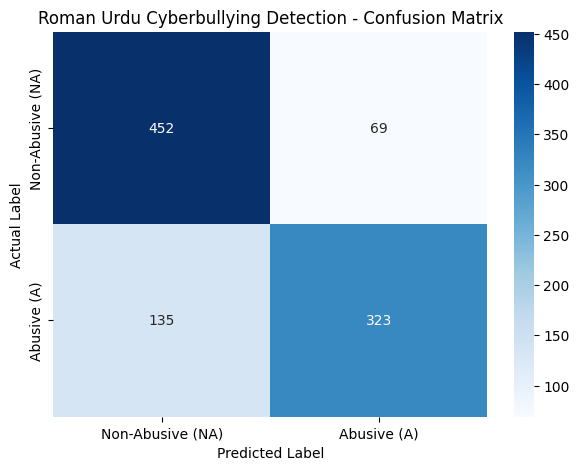

In [21]:

from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["NA", "A"])

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Abusive (NA)", "Abusive (A)"],
    yticklabels=["Non-Abusive (NA)", "Abusive (A)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Roman Urdu Cyberbullying Detection - Confusion Matrix")

plt.show()


In [22]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create improved pipeline
model_v2 = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train model
model_v2.fit(X_train, y_train)

# Make predictions
y_pred_v2 = model_v2.predict(X_test)

# Evaluate model
accuracy_v2 = accuracy_score(y_test, y_pred_v2)

print("New Model Accuracy:",
      round(accuracy_v2 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_v2))


New Model Accuracy: 79.78 %

Classification Report:
              precision    recall  f1-score   support

           A       0.83      0.72      0.77       458
          NA       0.78      0.87      0.82       521

    accuracy                           0.80       979
   macro avg       0.80      0.79      0.79       979
weighted avg       0.80      0.80      0.80       979



In [24]:

# Experiment 2: Increase TF-IDF features

model_v3 = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train model
model_v3.fit(X_train, y_train)

# Predictions
y_pred_v3 = model_v3.predict(X_test)

# Evaluation
accuracy_v3 = accuracy_score(y_test, y_pred_v3)

print("Model 3 Accuracy:",
      round(accuracy_v3 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_v3))



# Experiment 3: Class-balanced Logistic Regression

model_v4 = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train model
model_v4.fit(X_train, y_train)

# Predictions
y_pred_v4 = model_v4.predict(X_test)

# Evaluate
accuracy_v4 = accuracy_score(y_test, y_pred_v4)

print("Model 4 Accuracy:",
      round(accuracy_v4 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_v4))


Model 3 Accuracy: 79.57 %

Classification Report:
              precision    recall  f1-score   support

           A       0.83      0.70      0.76       458
          NA       0.77      0.88      0.82       521

    accuracy                           0.80       979
   macro avg       0.80      0.79      0.79       979
weighted avg       0.80      0.80      0.79       979

Model 4 Accuracy: 79.57 %

Classification Report:
              precision    recall  f1-score   support

           A       0.80      0.75      0.77       458
          NA       0.79      0.84      0.81       521

    accuracy                           0.80       979
   macro avg       0.80      0.79      0.79       979
weighted avg       0.80      0.80      0.80       979



Selected Model: Model 4
Accuracy: 79.57 %

Classification Report:
              precision    recall  f1-score   support

           A       0.80      0.75      0.77       458
          NA       0.79      0.84      0.81       521

    accuracy                           0.80       979
   macro avg       0.80      0.79      0.79       979
weighted avg       0.80      0.80      0.80       979



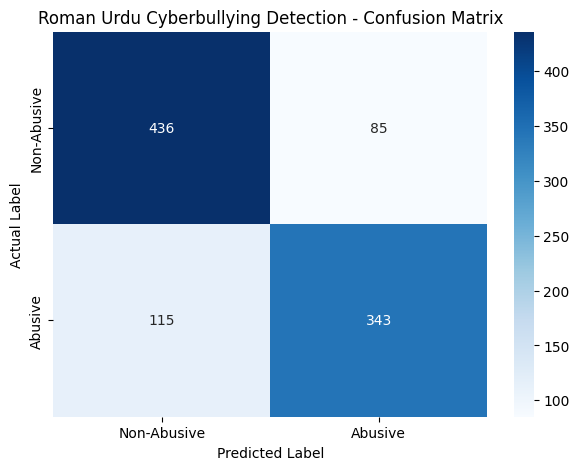

In [26]:
# Select the final model
best_model = model_v4

# Generate final predictions
best_y_pred = best_model.predict(X_test)

# Evaluate selected model
from sklearn.metrics import accuracy_score, classification_report

print("Selected Model: Model 4")
print("Accuracy:", round(accuracy_score(y_test, best_y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, best_y_pred))

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    best_y_pred,
    labels=["NA", "A"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Abusive", "Abusive"],
    yticklabels=["Non-Abusive", "Abusive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Roman Urdu Cyberbullying Detection - Confusion Matrix")

plt.show()

In [27]:
# New Roman Urdu comments for testing

new_comments = [
    "Tum bohot achay insan ho",
    "Tum bilkul jahil ho",
    "Aap ki baat bohot achi hai",
    "Tum bewakoof ho",
    "Mujhe tumhari madad achi lagi",
    "Chup karo tum pagal ho"
]

# Apply the same text cleaning function
cleaned_comments = [
    clean_text(comment) for comment in new_comments
]

# Predict using selected model
predictions = best_model.predict(cleaned_comments)

# Display results
for comment, prediction in zip(new_comments, predictions):

    if prediction == "A":
        result = "Abusive"
    else:
        result = "Non-Abusive"

    print("Comment:", comment)
    print("Prediction:", result)
    print("-" * 40)

Comment: Tum bohot achay insan ho
Prediction: Non-Abusive
----------------------------------------
Comment: Tum bilkul jahil ho
Prediction: Abusive
----------------------------------------
Comment: Aap ki baat bohot achi hai
Prediction: Non-Abusive
----------------------------------------
Comment: Tum bewakoof ho
Prediction: Abusive
----------------------------------------
Comment: Mujhe tumhari madad achi lagi
Prediction: Non-Abusive
----------------------------------------
Comment: Chup karo tum pagal ho
Prediction: Abusive
----------------------------------------


In [28]:
import joblib

# Save trained model
joblib.dump(
    best_model,
    "/kaggle/working/roman_urdu_cyberbullying_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [29]:
# Load saved model
loaded_model = joblib.load(
    "/kaggle/working/roman_urdu_cyberbullying_model.pkl"
)

# Test loaded model
test_comment = "Tum bohot achay insan ho"

# Clean the comment before prediction
cleaned_comment = clean_text(test_comment)

prediction = loaded_model.predict([cleaned_comment])

print("Comment:", test_comment)
print("Prediction:", prediction[0])

Comment: Tum bohot achay insan ho
Prediction: NA


In [36]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

from sklearn.svm import LinearSVC
# Pipeline mein:
('clf', LinearSVC(class_weight='balanced', max_iter=2000))

TfidfVectorizer(max_features=10000, ngram_range=(1,2), min_df=2)

TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5), max_features=10000)

TfidfVectorizer(analyzer='char_wb', max_features=10000, ngram_range=(2, 4))

from sklearn.svm import LinearSVC
# Pipeline mein:
('clf', LinearSVC(class_weight='balanced', max_iter=2000))

# Logistic Regression ke saath
y_proba = model.predict_proba(X_test)[:, 1]  # A class ki probability
y_pred_new = (y_proba >= 0.4).astype(int)  # 0.4 threshold

              precision    recall  f1-score   support

           A       0.82      0.71      0.76       458
          NA       0.77      0.87      0.82       521

    accuracy                           0.79       979
   macro avg       0.80      0.79      0.79       979
weighted avg       0.80      0.79      0.79       979



Accuracy: 0.8526740665993946

               precision    recall  f1-score   support

           A       0.84      0.85      0.84       467
          NA       0.86      0.86      0.86       524

    accuracy                           0.85       991
   macro avg       0.85      0.85      0.85       991
weighted avg       0.85      0.85      0.85       991

Model saved!


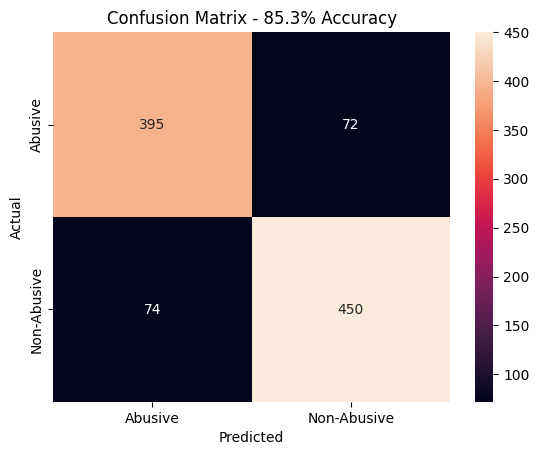

In [46]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# 1. Data load — SAHI PATH
df = pd.read_csv(
    '/kaggle/input/datasets/mirfanshahid/roman-urdu-abusive-comment-dataset-5000-comments/Cyber Dataset.csv',
    encoding='latin-1'
)

# 2. Labels saaf karein
df['Classes'] = df['Classes'].str.strip().str.upper()
df['Classes'] = df['Classes'].fillna('NA')

# 3. Duplicates hataayein
df = df.drop_duplicates(subset=['Comments'])

# 4. Text clean
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_comments'] = df['Comments'].apply(clean_text)

# 5. Features aur target
X = df['clean_comments']
y = df['Classes']

# 6. Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. Naya Pipeline
model = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', max_features=10000, ngram_range=(2, 4))),
    ('clf', LinearSVC(class_weight='balanced', max_iter=2000))
])

# 8. Train
model.fit(X_train, y_train)

# 9. Predict
y_pred = model.predict(X_test)

# 10. Result
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\n", classification_report(y_test, y_pred))


import pickle
with open('roman_urdu_cyberbullying_model.pkl', 'wb') as f:
    pickle.dump(model, f)
print("Model saved!")

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=['A', 'NA'])
sns.heatmap(cm, annot=True, fmt='d', 
            xticklabels=['Abusive', 'Non-Abusive'],
            yticklabels=['Abusive', 'Non-Abusive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - 85.3% Accuracy')
plt.show()

In [47]:
print("Dataset Shape:", df.shape)

print("\nClass Distribution:")
print(df["Classes"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Cleaned Comments:")
print(df["clean_comments"].duplicated().sum())

print("\nConflicting Labels:")
print(
    (df.groupby("clean_comments")["Classes"].nunique() > 1).sum()
)

Dataset Shape: (4951, 3)

Class Distribution:
Classes
NA    2617
A     2334
Name: count, dtype: int64

Missing Values:
Comments          0
Classes           0
clean_comments    0
dtype: int64

Duplicate Cleaned Comments:
58

Conflicting Labels:
1


In [51]:
# 1. Check conflicting labels
conflicts = df.groupby("clean_comments")["Classes"].nunique()

conflict_comments = conflicts[conflicts > 1].index

print("Conflicting comments:", len(conflict_comments))

# 2. Remove all conflicting comments
df = df[
    ~df["clean_comments"].isin(conflict_comments)
].copy()

# 3. Remove duplicate cleaned comments
df = df.drop_duplicates(
    subset=["clean_comments"],
    keep="first"
)

# 4. Reset index
df = df.reset_index(drop=True)

# 5. Check final dataset
print("Final Dataset Shape:", df.shape)

print("\nClass Distribution:")
print(df["Classes"].value_counts())

print("\nRemaining Duplicates:")
print(df["clean_comments"].duplicated().sum())

X = df["clean_comments"]
y = df["Classes"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char_wb",
        max_features=10000,
        ngram_range=(2, 4)
    )),
    ("clf", LinearSVC(
        class_weight="balanced",
        max_iter=2000
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\n", classification_report(y_test, y_pred))

import joblib

joblib.dump(
    model,
    "/kaggle/working/roman_urdu_cyberbullying_model.pkl"
)

print("Cleaned LinearSVC model saved successfully!")

loaded_model = joblib.load(
    "/kaggle/working/roman_urdu_cyberbullying_model.pkl"
)

test_comment = "Tum bilkul jahil ho"

cleaned_comment = clean_text(test_comment)

prediction = loaded_model.predict([cleaned_comment])

print("Comment:", test_comment)
print("Prediction:", prediction[0])

Conflicting comments: 0
Final Dataset Shape: (4892, 3)

Class Distribution:
Classes
NA    2602
A     2290
Name: count, dtype: int64

Remaining Duplicates:
0
Accuracy: 0.8335035750766088

               precision    recall  f1-score   support

           A       0.83      0.81      0.82       458
          NA       0.84      0.86      0.85       521

    accuracy                           0.83       979
   macro avg       0.83      0.83      0.83       979
weighted avg       0.83      0.83      0.83       979

Cleaned LinearSVC model saved successfully!
Comment: Tum bilkul jahil ho
Prediction: A
